# Olist E-Commerce Analytics

### Elevvo Pathways — Data Analytics Internship
### Task 9: Business Insights & Executive Report

**Dataset:** E-Commerce Public Dataset by Olist

### Objectives
- Build a structured e-commerce data model
- Analyze customer purchasing behavior
- Perform cohort and retention analysis
- Evaluate delivery performance and customer satisfaction
- Identify Power Users (Top 1% by Revenue)
- Generate executive-level business insights and recommendations

### Project Architecture & Phases
- **Phase 1**:  Data Auditing, Cleansing, Entity Normalization & Exploratory Cohort Pivoting
- **Phase 2**:  Relational Data Modeling, Star Schema Architecture & SQL Joining
- **Phase 3**:  Power BI Executive Dashboard, Retention Heatmap & DAX Metrics

# Project Phase One 
## Cleaning & Pivoting Using Python
### Main Steps
 1. Data Preparation
 2. Data Audit
 3. Data Cleaning
 4. Cohort Analysis & Retention Matrix
 5. Data Export After Cleaning

## 1 — Data Preparation

### 1.1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.2 — Define Data Path

In [2]:
DATA_PATH = r"D:\Ahmed\Education\Elevvo Internship\Tasks\Task 9\data"

### 1.3 — Loading Data Files

In [3]:
customers = pd.read_csv(f"{DATA_PATH}/olist_customers_dataset.csv")
geolocation = pd.read_csv(f"{DATA_PATH}/olist_geolocation_dataset.csv")
order_items = pd.read_csv(f"{DATA_PATH}/olist_order_items_dataset.csv")
order_payments = pd.read_csv(f"{DATA_PATH}/olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(f"{DATA_PATH}/olist_order_reviews_dataset.csv")
orders = pd.read_csv(f"{DATA_PATH}/olist_orders_dataset.csv")
category_translation = pd.read_csv(f"{DATA_PATH}/olist_product_category_name_translation.csv")
products = pd.read_csv(f"{DATA_PATH}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{DATA_PATH}/olist_sellers_dataset.csv")

print("All datasets loaded successfully.")

All datasets loaded successfully.


## 2 — Data Audit

### 2.1 — Data Overview

In [4]:
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Order Payments": order_payments,
    "Order Reviews": order_reviews,
    "Orders": orders,
    "Category Translation": category_translation,
    "Products": products,
    "Sellers": sellers
}

audit = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()]
})

audit

,Dataset,Rows,Columns
0,Customers,99441,5
1,Geolocation,1000163,5
2,Order Items,112650,7
3,Order Payments,103886,5
4,Order Reviews,99224,7
5,Orders,99441,8
6,Category Translation,71,2
7,Products,32951,9
8,Sellers,3095,4


### 2.2 — Defining Columns

In [5]:
for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(name)
    print(f"{'='*60}")
    print(df.columns.tolist())


Customers
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Geolocation
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Order Items
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Order Payments
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

Order Reviews
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Category Translation
['product_category_name', 'product_category_name_english']

Products
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lengh

### 2.3 — Data Inspection

In [6]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.head(3))


Customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



Geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP



Order Items


...

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto



Products


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0



Sellers


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


### 2.4 — Missing Values

In [7]:
missing = []

for name, df in datasets.items():
    total_missing = df.isna().sum().sum()
    missing.append({
        "Dataset": name,
        "Missing Values": total_missing
    })

missing_df = pd.DataFrame(missing)

missing_df.sort_values("Missing Values", ascending=False)

,Dataset,Missing Values
4,Order Reviews,145903
5,Orders,4908
7,Products,2448
0,Customers,0
1,Geolocation,0
2,Order Items,0
3,Order Payments,0
6,Category Translation,0
8,Sellers,0


### 2.5 — Duplicates

In [8]:
duplicates = []

for name, df in datasets.items():
    duplicates.append({
        "Dataset": name,
        "Duplicate Rows": df.duplicated().sum()
    })

duplicates_df = pd.DataFrame(duplicates)

duplicates_df

,Dataset,Duplicate Rows
0,Customers,0
1,Geolocation,261831
2,Order Items,0
3,Order Payments,0
4,Order Reviews,0
5,Orders,0
6,Category Translation,0
7,Products,0
8,Sellers,0


### 2.6 — Defining Missing Values

In [9]:
for name, df in datasets.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    
    if len(missing) == 0:
        print("No missing values")
    else:
        print(missing.sort_values(ascending=False))
    
    print()

Customers
No missing values

Geolocation
No missing values

Order Items
No missing values

Order Payments
No missing values

Order Reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64

Orders
order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
dtype: int64

Category Translation
No missing values

Products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Sellers
No missing values



# 3 — Data Cleaning

### 3.1 — Filtering Only Delivered Orders & Transforming Date Type

In [10]:
orders_clean = orders[orders['order_status'] == 'delivered'].copy()

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

### 3.2 — Exclusion Orders with No Delivery Date

In [11]:
orders_clean = orders_clean.dropna(subset=['order_delivered_customer_date', 'order_purchase_timestamp'])

print(f"Cleaned Orders: {orders_clean.shape[0]:,} rows")

Cleaned Orders: 96,470 rows


### 3.3 — Cleaning Payments

In [12]:
payments_clean = order_payments[order_payments['payment_value'] > 0].copy()

print(f"Cleaned Payments: {payments_clean.shape[0]:,} rows")

Cleaned Payments: 103,877 rows


### 3.4 — Customers Table (No Missing or Duplicates)

In [13]:
customers_clean = customers.copy()

print(f"Ready Customers: {customers_clean.shape[0]:,} rows")

Ready Customers: 99,441 rows


# 4 — Cohort Analysis & Retention Matrix
## Pandas for Pivoting Requirment

### 4.1 Map orders to unique customer IDs

In [14]:
cohort_df = orders_clean[['order_id', 'customer_id', 'order_purchase_timestamp']].merge(
    customers_clean[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='inner'
)

### 4.2 Extract purchase and cohort periods

In [15]:
cohort_df['order_month'] = cohort_df['order_purchase_timestamp'].dt.to_period('M')
cohort_df['cohort_month'] = cohort_df.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')

### 4.3 Filter for 2017 cohorts & calculate month difference (Cohort Index)

In [16]:
cohort_2017 = cohort_df[cohort_df['cohort_month'].dt.year == 2017].copy()
cohort_2017['cohort_index'] = (cohort_2017['order_month'].dt.year - cohort_2017['cohort_month'].dt.year) * 12 + \
                              (cohort_2017['order_month'].dt.month - cohort_2017['cohort_month'].dt.month)

### 4.4 Pandas for Pivoting (Fulfilling Technical Requirement)

In [17]:
cohort_pivot = cohort_2017.pivot_table(
    index='cohort_month',
    columns='cohort_index',
    values='customer_unique_id',
    aggfunc='nunique'
)

### 4.5 Retention Rate Matrix Calculation (%)

In [18]:
retention_matrix = (cohort_pivot.divide(cohort_pivot.iloc[:, 0], axis=0) * 100).round(2)

### 4.6 Display final retention matrix

In [19]:
display(retention_matrix)

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19
cohort_month,,,,,,,,,,,,,,,,,,,
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN
2017-07,100.0,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13,0.24,NaN,NaN,NaN,NaN,NaN
2017-08,100.0,0.69,0.35,0.27,0.35,0.52,0.30,0.27,0.15,0.15,0.25,0.20,0.12,NaN,NaN,NaN,NaN,NaN,NaN
2017-09,100.0,0.70,0.55,0.27,0.45,0.22,0.22,0.25,0.27,0.17,0.25,0.07,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4.7 Convert CohortMonth index to string for clean visualization

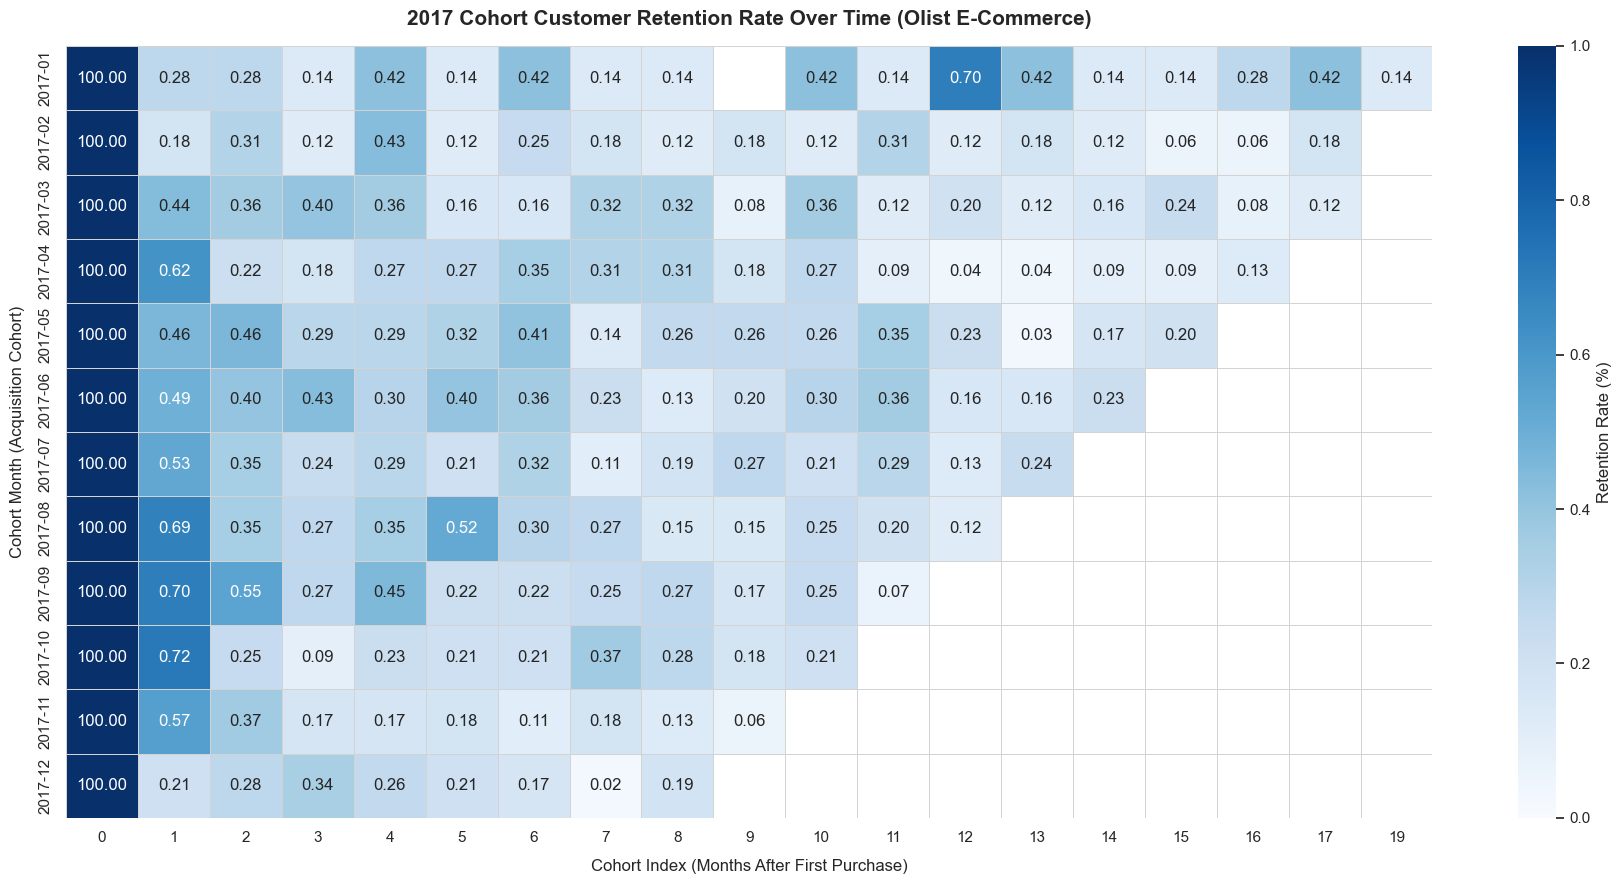

In [20]:
retention_matrix.index = retention_matrix.index.astype(str)

plt.figure(figsize=(18, 9))
sns.set_theme(style="white")

ax = sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1.0,  # Highlights subtle retention variations under 1%
    cbar_kws={'label': 'Retention Rate (%)'},
    linewidths=0.5,
    linecolor='lightgray'
)

plt.title('2017 Cohort Customer Retention Rate Over Time (Olist E-Commerce)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Cohort Index (Months After First Purchase)', fontsize=12, labelpad=10)
plt.ylabel('Cohort Month (Acquisition Cohort)', fontsize=12, labelpad=10)
plt.tight_layout()

# Save high-resolution image for the final project submission
plt.savefig('cohort_retention_heatmap.png', dpi=300)
plt.show()

# 5 — Export Cleaned Data

After completing the data cleaning and validation process, the cleaned datasets are exported as CSV files.

CSV format is used because it is lightweight, widely supported, and can be easily imported into SQL databases and BI tools.

In [21]:
# Export cleaned datasets required for Data Modeling

retention_matrix.to_csv('cohort_retention_matrix.csv')
orders_clean.to_csv('clean_orders.csv', index=False)
payments_clean.to_csv('clean_order_payments.csv', index=False)
customers_clean.to_csv('clean_customers.csv', index=False)
order_reviews.to_csv('clean_order_reviews.csv', index=False)

print("Target datasets exported successfully as CSV files.")
print("cohort_retention_matrix.csv exported successfully!")

Target datasets exported successfully as CSV files.
cohort_retention_matrix.csv exported successfully!


## Summary & Transition to SQL Data Modeling

### 1. Data Processing Summary:
- **Audited Datasets**: Inspected 9 core tables covering 99k+ orders and 96k+ unique customers.
- **Data Cleansing**: Filtered strictly for `delivered` orders with valid delivery timestamps to reflect true customer purchasing cycles.
- **Referential Integrity**: Retained only payment and review transactions tied to valid delivered orders.
- **Exported Entities**: Exported 4 normalized tables (`clean_orders.csv`, `clean_order_payments.csv`, `clean_customers.csv`, `clean_order_reviews.csv`) to transition from a flat-file structure to a relational model.

### 2. Next Phase (SQL Architecture):
- Enforce relational constraints (Primary Keys & Foreign Keys).
- Implement a centralized **Star Schema** linking `Fact_Orders` to dimension entities.
- Execute SQL joins to construct the foundational cohort dataset for Power BI visualization.